In [3]:
from rdkit import Chem
import pickle
import os
import json
import joblib
import numpy as np
import xgboost


In [4]:
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [7]:
reactions_dir = "reactions"
reaction_id = 5
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 6 pickle files to RDKit Mol objects.


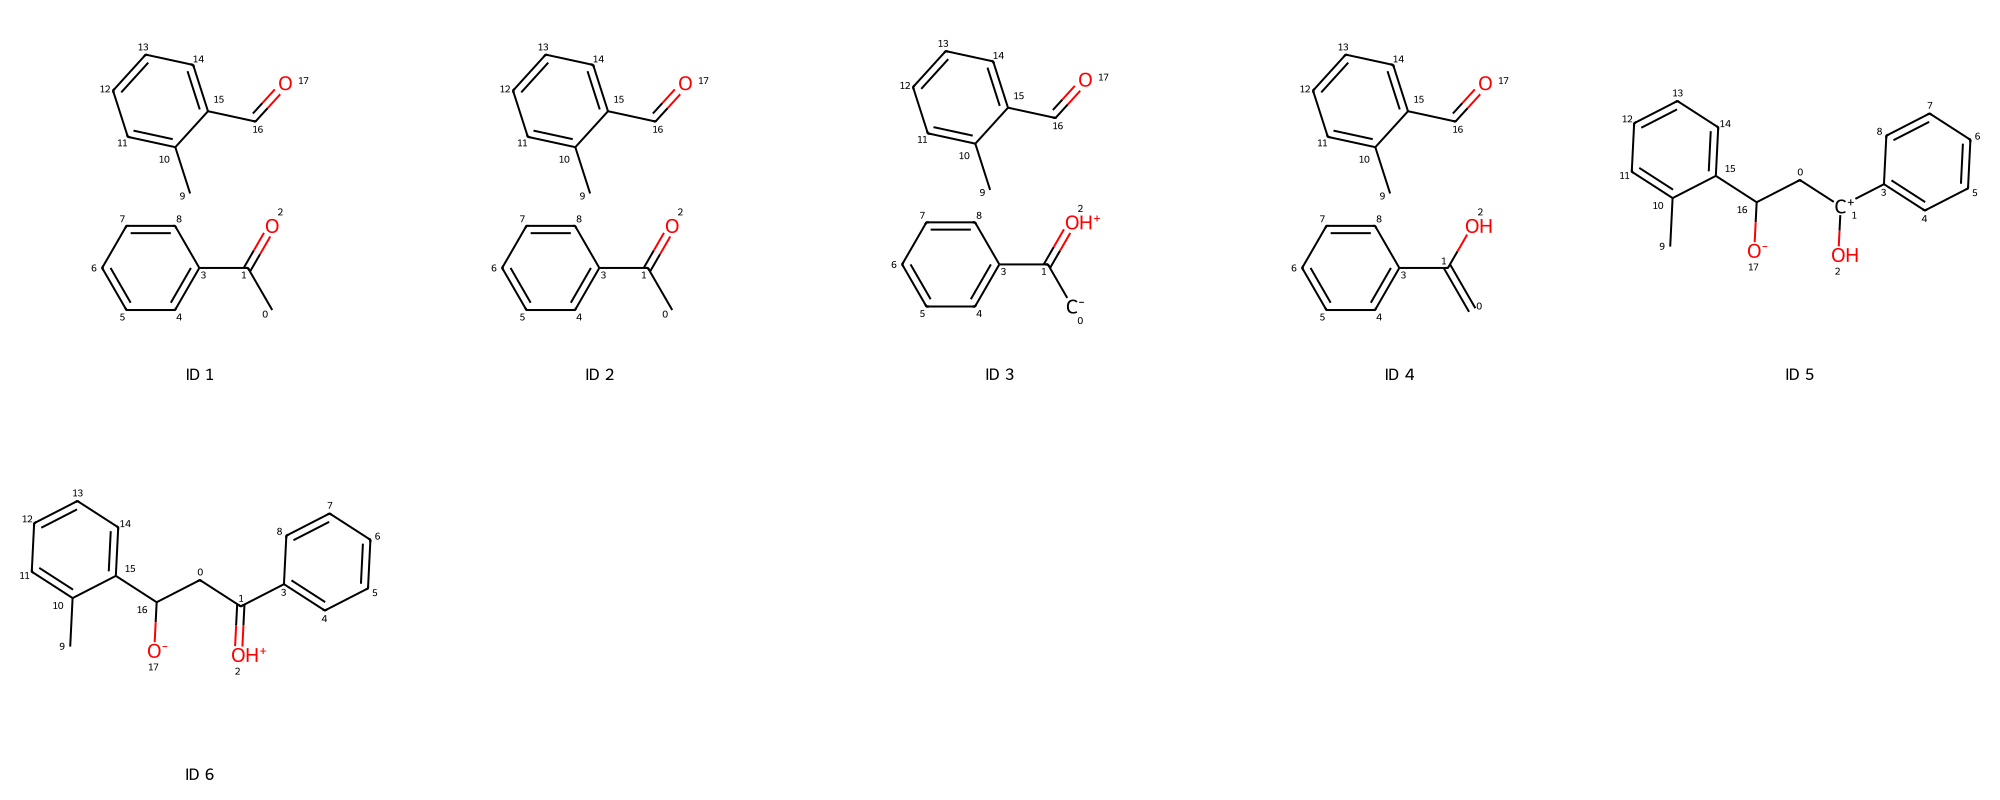

In [8]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(400, 400), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

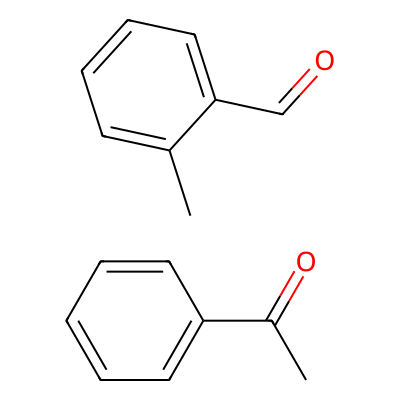

In [9]:
mol_problem = mol_objects[1]
mol_problem
Chem.SanitizeMol(mol_problem)
Chem.Draw.IPythonConsole.molSize = (400,400)
mol_problem

In [10]:
mol_arom = mol_objects[0]
Chem.SanitizeMol(mol_arom)
for a in mol_arom.GetAromaticAtoms():
    print(a.GetIdx())

3
4
5
6
7
8
10
11
12
13
14
15


In [11]:
training_id = 16
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

FileNotFoundError: [Errno 2] No such file or directory: 'training/16/data.json'

In [12]:
Chem.Draw.MolsToGridImage(t_mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(t_mol_objects))], drawOptions=opt)

[14:18:57] 

****
Pre-condition Violation
no draw context
Violation occurred on line 211 in file /project/build/temp.linux-x86_64-cpython-313/rdkit/Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
Failed Expression: dp_cr
----------
Stacktrace:
----------
****



RuntimeError: Pre-condition Violation
	no draw context
	Violation occurred on line 211 in file Code/GraphMol/MolDraw2D/MolDraw2DCairo.cpp
	Failed Expression: dp_cr
	RDKIT: 2025.03.2
	BOOST: 1_85


In [13]:
def make_atom_fingerprint(atom):

    if atom is None:
        return [0] * 34

    # Charge bitstring
    charge_bitstring = [0] * 3
    if atom.GetFormalCharge() < 0:
        charge_bitstring[0] = 1
    elif atom.GetFormalCharge() == 0:
        charge_bitstring[1] = 1
    elif atom.GetFormalCharge() > 0:
        charge_bitstring[2] = 1

    # H bitstring
    h_number_bitstring = [0] * 4
    if atom.GetTotalNumHs() == 0:
        h_number_bitstring[0] = 1
    elif atom.GetTotalNumHs() == 1:
        h_number_bitstring[1] = 1
    elif atom.GetTotalNumHs() == 2:
        h_number_bitstring[2] = 1
    elif atom.GetTotalNumHs() > 2:
        h_number_bitstring[3] = 1

    # Hybridization bitstring
    hybridization_bitstring = [0] * 3
    if atom.GetHybridization() == Chem.rdchem.HybridizationType.SP:
        hybridization_bitstring[0] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP2:
        hybridization_bitstring[1] = 1
    elif atom.GetHybridization() == Chem.rdchem.HybridizationType.SP3:
        hybridization_bitstring[2] = 1

    # Element bitstring
    # [AlkMet, B, C, N, O, F, Mg, Al, Si, P, S, Cl, Br, I, Met]
    ptable = Chem.GetPeriodicTable()
    element_bitstring = [0] * 15
    dict_elements = { 5: 1,
                      6: 2,
                      7: 3,
                      8: 4,
                      9: 5,
                      12: 6,
                      13: 7,
                      14: 8,
                      15: 9,
                      16: 10,
                      17: 11,
                      35: 12,
                      53: 13}
    atm_num = atom.GetAtomicNum()
    if atm_num in dict_elements:
        element_bitstring[dict_elements[atm_num]] = 1
    elif ptable.GetNOuterElecs(atm_num) == 1:
        element_bitstring[0] = 1
    elif atm_num <= 30 and atm_num >= 20:
        element_bitstring[14] = 1

    # aromaticity bitstring
    new_mol = Chem.Mol(atom.GetOwningMol())
    Chem.SetAromaticity(new_mol)
    if new_mol.GetAtomWithIdx(atom.GetIdx()).GetIsAromatic():
        aromatic_bit = [1]
    else:
        aromatic_bit = [0]

    # adjacency bitstring
    # [C+, C-, CH, C-EN, C=EN, EN, EP]
    adjecency_bitstring = [0] * 8
    for a in atom.GetNeighbors():
        if a.GetAtomicNum() == 6:
            if a.GetFormalCharge() > 0:
                adjecency_bitstring[0] = 1
            elif a.GetFormalCharge() < 0:
                adjecency_bitstring[1] = 1
            if a.GetTotalNumHs() > 0:
                adjecency_bitstring[2] = 1
            for a2 in a.GetNeighbors():
                if electronegativity_dict[a2.GetAtomicNum()] > 2.55:
                    for b in a.GetBonds():
                        if b.GetOtherAtom(a).GetIdx() == a2.GetIdx():
                            if b.GetBondTypeAsDouble() == 1:
                                adjecency_bitstring[3] = 1
                            elif b.GetBondTypeAsDouble() >= 2:
                                adjecency_bitstring[4] = 1
        elif electronegativity_dict[a.GetAtomicNum()] > 2.55:
            adjecency_bitstring[5] = 1
        elif electronegativity_dict[a.GetAtomicNum()] < 2.05:
            adjecency_bitstring[6] = 1
 
    

    total_bit_string = charge_bitstring + h_number_bitstring + hybridization_bitstring + element_bitstring + aromatic_bit + adjecency_bitstring
    return total_bit_string

   
def make_bond_fingerprint(bond):
    # bond type bitstring
    # [single, double, triple]
    bond_type_bitstring = [0] * 4
    if not bond:
        return bond_type_bitstring
    if bond.GetBondTypeAsDouble() == 1:
        bond_type_bitstring[0] = 1
    elif bond.GetBondTypeAsDouble() == 2:
        bond_type_bitstring[1] = 1
    elif bond.GetBondTypeAsDouble() == 3:
        bond_type_bitstring[2] = 1
    return bond_type_bitstring


def new_bond_fingerprint(mol, a1_idx, a2_idx):
    if a1_idx == None or a2_idx is None:
        return [0] * 5
    a1 = mol.GetAtomWithIdx(a1_idx)
    a2 = mol.GetAtomWithIdx(a2_idx)
    # ring size bitstring
    # [3, 4, 5, 6, 7+]
    ring_size_bitstring = [0] * 5
    fragments = Chem.GetMolFrags(mol)
    for f in fragments:
        if a1.GetIdx() in f and a2.GetIdx() in f:
            if a1.GetIdx() == a2.GetIdx():
                continue
            len_path = len(Chem.GetShortestPath(mol, a1.GetIdx(), a2.GetIdx()))
            if len_path == 3:
                ring_size_bitstring[0] = 1
            elif len_path == 4:
                ring_size_bitstring[1] = 1
            elif len_path == 5:
                ring_size_bitstring[2] = 1
            elif len_path == 6:
                ring_size_bitstring[3] = 1
            elif len_path >= 7:
                ring_size_bitstring[4] = 1
    return ring_size_bitstring


In [14]:
# Data analysis

arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom'
}


training_dir = "training"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []

for subdir in subdirs:
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    for id, info in choices.items():
        # bitvector for the mechanism
        mech_type = [0] * 11
        mech_type[info['mechanism'][0]] = 1
        if info['mechanism'][0] < 4 or True:
            atom_fps = []
            for i in range(1, 5):
                if info['mechanism'][i] is None:
                   atom_fps.append(make_atom_fingerprint(None))
                else:
                    atom_fps.append(make_atom_fingerprint(sm.GetAtomWithIdx(info['mechanism'][i])))
            if info['mechanism'][3]:
                b1 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][1], info['mechanism'][3]))
            else:
                b1 = [0] *4
            if info['mechanism'][4]:
                b2 = make_bond_fingerprint(sm.GetBondBetweenAtoms(info['mechanism'][2], info['mechanism'][4]))
            else:
                b2 = [0] *4
            r = new_bond_fingerprint(sm, info['mechanism'][1], info['mechanism'][2])
            sum_finger_print = mech_type + atom_fps[0] + atom_fps[1] + atom_fps[2] + atom_fps[3] + b1 + b2 + r
            bitvectors.append(sum_finger_print)
            outcomes.append(info['probable'])
            # Track the origin of each bitvector
            with open("bitvector_origins.txt", "a") as origin_file:
                origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")



FileNotFoundError: [Errno 2] No such file or directory: 'training'

In [85]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score

In [86]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
#joblib.dump(clf, 'model.pkl')

Accuracy: 0.8912466843501327
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.97      0.94       322
           1       0.72      0.42      0.53        55

    accuracy                           0.89       377
   macro avg       0.81      0.70      0.73       377
weighted avg       0.88      0.89      0.88       377



In [87]:
from xgboost import XGBClassifier

In [88]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 12, eval_metric='logloss')
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'xg_model.pkl')

              precision    recall  f1-score   support

           0       0.96      0.93      0.95       325
           1       0.64      0.79      0.71        52

    accuracy                           0.91       377
   macro avg       0.80      0.86      0.83       377
weighted avg       0.92      0.91      0.91       377



['xg_model.pkl']

In [ ]:
precisions =[]
recalls = []
f1_scores = []
from sklearn.metrics import f1_score
pos_weight = 15

iter = 10
for i in range(pos_weight):
    precision = 0
    recall = 0
    f1 = 0
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        # Get recall for positive class only (label=1)
        recall += recall_score(y_test, y_pred, pos_label=1)/iter
        precision += precision_score(y_test, y_pred, pos_label=1)/iter
        f1 += f1_score(y_test, y_pred, pos_label=1)/iter
    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)


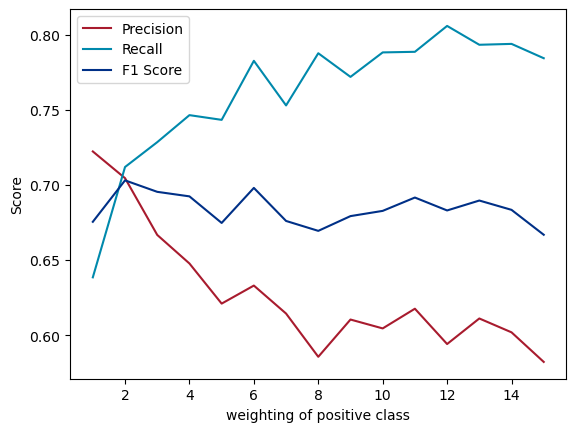

In [213]:
from matplotlib import pyplot as plt
from cycler import cycler
plt.plot(range(1, pos_weight+1), precisions, label='Precision')
plt.plot(range(1, pos_weight+1), recalls, label='Recall')
plt.plot(range(1, pos_weight+1), f1_scores, label='F1 Score')
plt.rc('axes', prop_cycle=cycler('color', custom_c))
plt.xlabel('weighting of positive class')
plt.ylabel('Score')
plt.legend()
#plt.show()
plt.savefig('pos_weighting.png', dpi=300)

In [81]:
import seaborn as sns


plt.figure(figsize=(10, 6))
sns.heatmap(bitvectors, cmap="Greys", cbar=False)
plt.xlabel("Bit Index")
plt.ylabel("Sample Index")
plt.title("Bitvector Activity")
plt.show()

NameError: name 'plt' is not defined

In [15]:
np.sum(np.array(bitvectors), axis=0)

array([  20,  395,    0,  341,  318,  203,    6,   15,    0,    0,  134,
       1158,    6,  493,  585,  166,   54,   12,  835,  451,    0,   21,
        640,  124,  283,    6,    0,    0,    0,    0,    2,   96,   95,
         31,    0,  284,   66,   35,  754,  406,  308,  124,  139,    0,
         29, 1183,   86,  279,  648,  184,  187,   41,  816,  441,    0,
         19, 1083,   51,   54,    0,   37,   19,    0,    0,    1,   12,
         12,   10,    0,  344,   99,   67,  982,  294,  221,  412,   57,
          0,   36,  514,    0,    0,  214,  451,    4,    0,  314,  160,
         55,   26,    7])

In [82]:
np.array(bitvectors).shape

(1506, 91)

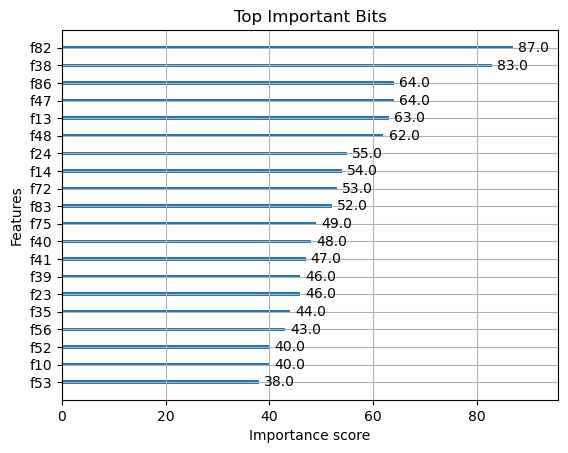

In [16]:
clf = joblib.load('xg_model.pkl')
xgboost.plot_importance(clf, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [62]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.8992042440318302
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.95      0.94       324
           1       0.65      0.60      0.63        53

    accuracy                           0.90       377
   macro avg       0.79      0.78      0.78       377
weighted avg       0.90      0.90      0.90       377



In [19]:
%run ml_tools/get_feature.py 37

Feature at index 37: Atom 1 - Adjacency Bit


Can we learn chemical reactions from the reaction space

In [23]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances


mask = np.array(outcomes) == 1
X = np.array(bitvectors)[mask]


# Use Jaccard distance
distances = pairwise_distances(np.array(bitvectors), metric='jaccard')

# Fit kNN using precomputed distances
#knn = NearestNeighbors(n_neighbors=2, metric='precomputed')
#knn.fit(distances)

# Find nearest neighbors of a specific vector
#dists, indices = knn.kneighbors([distances[0]])
#print("Nearest neighbors of first bitstring:", indices)

/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [39]:
from sklearn.cluster import DBSCAN

# Compute Jaccard distance matrix
dist = pairwise_distances(X, metric='jaccard')

# Cluster using DBSCAN
clustering = DBSCAN(metric='precomputed', eps=0.2, min_samples=3)
labels = clustering.fit_predict(dist)

print("Cluster labels:", labels)

Cluster labels: [ 0  0  1  0  1 -1 -1 -1  2 -1 -1 -1  3  3 -1 -1 -1  1  4  4  4  4  1  4
  1 -1 -1 -1 -1 -1  3 -1 -1 -1 -1 -1  5 -1  6 -1  5  7  5  8  9 10 11  7
  5 -1 -1  7 -1  5  7 -1 -1  5  7  6  6 -1 -1  5  5 -1 -1 12  5 -1 -1 -1
 -1 12  6  5 13  8  5 10 11 -1 -1 -1 -1  5  9 -1  5 -1  9 10 -1  5 13 -1
  9  7  5 -1  7 -1 -1 -1 -1 -1 -1  5 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 13 -1 -1  5 -1 -1  7 -1 -1  3  5  9  9  9  7  7  7  7  7
  7  7  7  7  7  7  8 11 -1  3  3 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1 -1 -1
 -1 -1  2 -1  5 -1 -1 14 -1 -1 -1 14 -1 -1 -1 12 14 -1 -1 -1 -1 -1  6 -1
  5 -1 -1 -1 -1  5  9  7 -1 -1 -1 -1 -1 -1 -1  5 -1  9 -1  5  9 -1]


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [40]:
len(labels)

214

In [41]:
len(bitvectors)

1506

In [42]:
from collections import defaultdict

clusters = defaultdict(list)
for idx, label in enumerate(labels):
    clusters[label].append(idx)

for cluster_id, members in clusters.items():
    if cluster_id == -1:
        print(f"Noise points: {members}")
    else:
        print(f"Cluster {cluster_id}: {members}")

Cluster 0: [0, 1, 3]
Cluster 1: [2, 4, 17, 22, 24]
Noise points: [5, 6, 7, 9, 10, 11, 14, 15, 16, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 37, 39, 49, 50, 52, 55, 56, 61, 62, 65, 66, 69, 70, 71, 72, 81, 82, 83, 84, 87, 89, 92, 95, 99, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 129, 130, 132, 133, 152, 155, 156, 157, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 171, 173, 174, 176, 177, 178, 180, 181, 182, 185, 186, 187, 188, 189, 191, 193, 194, 195, 196, 200, 201, 202, 203, 204, 205, 206, 208, 210, 213]
Cluster 2: [8, 163, 170]
Cluster 3: [12, 13, 30, 134, 153, 154]
Cluster 4: [18, 19, 20, 21, 23]
Cluster 5: [36, 40, 42, 48, 53, 57, 63, 64, 68, 75, 78, 85, 88, 93, 98, 107, 128, 135, 172, 192, 197, 207, 211]
Cluster 6: [38, 59, 60, 74, 190]
Cluster 7: [41, 47, 51, 54, 58, 97, 100, 131, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 199]
Cluster 8: [43, 77, 150]
Cluster 9: [44, 86, 90, 96, 1

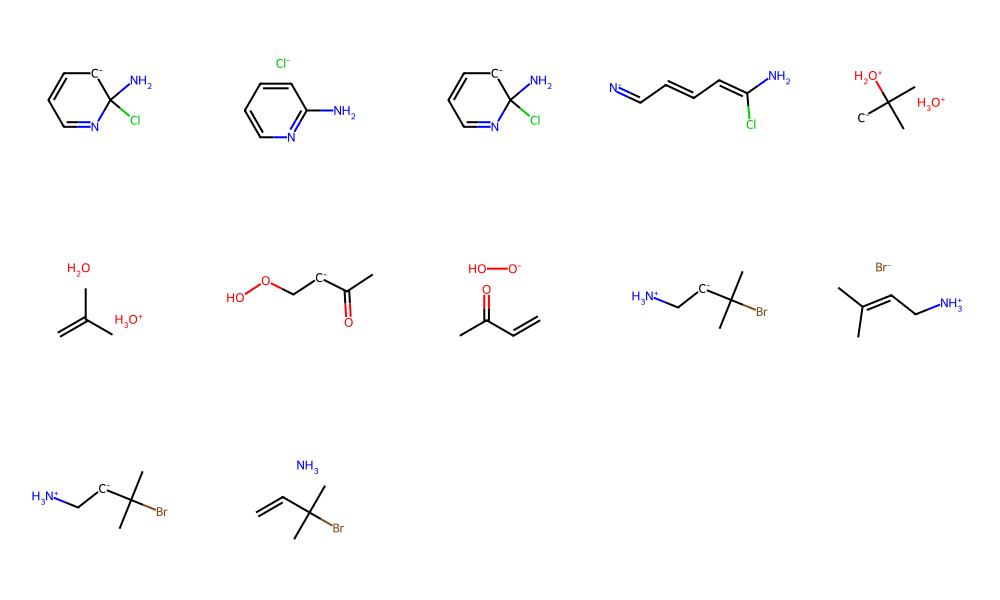

In [44]:
from rdkit.Chem import Draw

# Select a specific cluster to visualize (e.g., cluster_id)
cluster_members = clusters[3]

# For each member index, find the corresponding training directory

mols = []
legends = []
# subdirs is sorted list of training subdirectory names (as strings)
# cluster_members contains indices into the mask-filtered X (i.e., indices of probable outcomes)
# We need to map these indices back to the original subdirs

# First, get the indices of all probable outcomes in the original bitvectors list
probable_indices = np.where(mask)[0]

for idx in cluster_members:
    # Use bitvector_origins.txt to map idx to folder and choice id
    with open("bitvector_origins.txt", "r") as origin_file:
        for line in origin_file:
            parts = line.strip().split(",")
            if int(parts[0]) == probable_indices[idx]:
                folder_path = parts[1]
                subdir = os.path.basename(folder_path)
                mol_id = parts[2]
                break
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    mol_path = os.path.join(folder_path,  "mol_" + str(mol_id) + '.pkl')
    json_path = os.path.join(folder_path, 'data.json')
    # Load molecule
    with open(pkl_path, "rb") as f:
        mol = pickle.load(f)
        mols.append(mol)
    # Load probable mechanism info
    with open(mol_path, 'rb') as f:
        mol = pickle.load(f)
        mols.append(mol)
    legends.append(f"ID {subdir}")

# Visualize molecules with legends
Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200, 200))

In [126]:
clf = joblib.load('xg_model.pkl')

In [31]:
beckmann = Chem.MolFromSmiles('[OH2+]N=C1CCCCC1')
alkyl = Chem.MolFromSmiles('CC(C)(C)[CH2+]')
tert_brom = Chem.MolFromSmiles('CC1(Br)CCCCC1')
bv = Chem.MolFromSmiles('OOC1(O)CCCCC1')
bv_p = Chem.MolFromSmiles('[OH2+]OC1(O)CCCCC1')
r_aldol = Chem.MolFromSmiles('COC(C)([O-])C(C)(C)C(C)=O')
ohira_bestman = Chem.MolFromSmiles('CC(=[C])C1=CC=CC=C1')
diazo = Chem.MolFromSmiles('N#[N+]C1=CC=CC=C1')
brook = Chem.MolFromSmiles('CC(C[O-])[Si](C)(C)C')

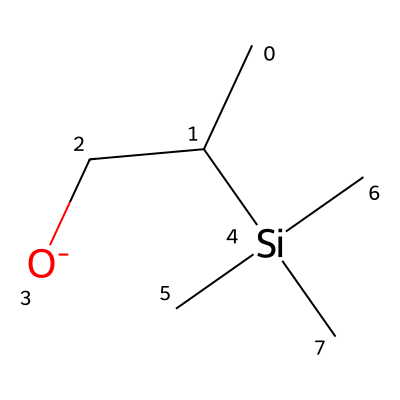

In [32]:
brook

In [17]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [23]:
def make_fingerprint(sm, mech):
    mech_type = [0] * 11
    mech_type[mech[0]] = 1
    atom_fps = []
    for i in range(1, 5):
        if mech[i] is None:
            atom_fps.append(make_atom_fingerprint(None))
        else:
            atom_fps.append(make_atom_fingerprint(sm.GetAtomWithIdx(mech[i])))
    if mech[3]:
        b1 = make_bond_fingerprint(sm.GetBondBetweenAtoms(mech[1], mech[3]))
    else:
        b1 = [0] * 4
    if mech[4]:
        b2 = make_bond_fingerprint(sm.GetBondBetweenAtoms(mech[2], mech[4]))
    else:
        b2 = [0] * 4
    r = new_bond_fingerprint(sm, mech[1], mech[2])
    sum_finger_print = mech_type + atom_fps[0] + atom_fps[1] + atom_fps[2] + atom_fps[3] + b1 + b2 + r
    return sum_finger_print

In [33]:
clf = joblib.load('xg_model.pkl')
mol = brook
arrow = [1, 3, 4, None, 1]
sum_finger_print = make_fingerprint(mol, arrow)

In [34]:
print(clf.predict(np.array([sum_finger_print]).reshape(1, -1)))

[1]


In [35]:
clf

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [196]:
outcomes.count(1)

214

In [197]:
len(outcomes)

1506

In [199]:
(1506-214)/214

6.037383177570093

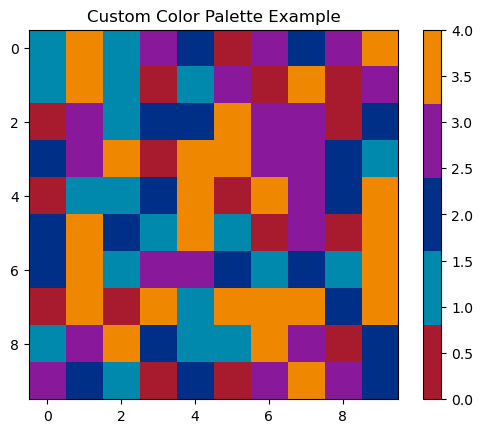

In [4]:
from matplotlib.colors import ListedColormap
import numpy as np

# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

# Example usage with matplotlib
import matplotlib.pyplot as plt

data = np.random.randint(0, len(custom_c), (10, 10))
plt.imshow(data, cmap=custom_cmap)
plt.colorbar()
plt.title("Custom Color Palette Example")
plt.show()

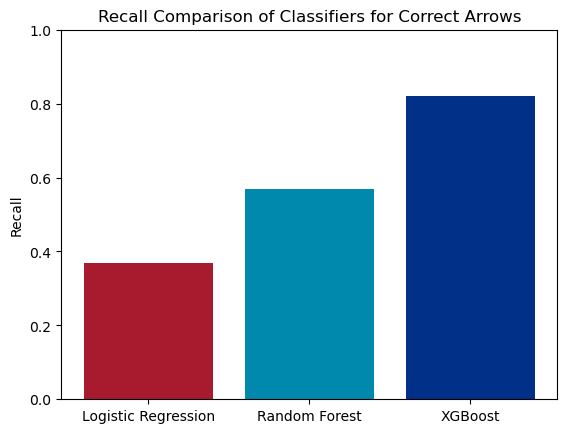

In [6]:
recalls = [0.37, 0.57, 0.82]
labels = ["Logistic Regression", "Random Forest", "XGBoost"]
plt.bar(labels, recalls, color=custom_c[:len(labels)])
plt.ylabel("Recall")
plt.title("Recall Comparison of Classifiers for Correct Arrows")
plt.ylim(0, 1)
plt.show()

In [2]:
from matplotlib import pyplot as plt